# 04 · The Same Model in PyTorch Geometric

**GNNs for Medicine — Lesson 4 of 5**

Track 1 built a working BBBP classifier from scratch in ~200 lines. Now we rebuild it with **PyTorch Geometric (PyG)** — the most widely used GNN library — in about 20. The point isn't just brevity: it's that **you now know what every line replaces.**

| From scratch (NB03) | PyTorch Geometric |
|---|---|
| `smiles_to_graph`, manual feature arrays | `MoleculeNet` dataset + `Data` objects |
| `normalized_adj` (Â = D⁻½(A+I)D⁻½) | built into `GCNConv` |
| `GCNLayer` = `Linear(Ahat @ H)` | `GCNConv(in, out)` |
| block-diagonal `make_batch` + `batch` vector | `DataLoader` (does it automatically) |
| manual `index_add_` mean pool | `global_mean_pool(x, batch)` |
| hand-written epoch loop | same loop, cleaner |

In [1]:
# In Colab, torch is preinstalled; add PyG. (First run downloads a few MB.)
!pip install -q torch-geometric rdkit

In [2]:
import warnings; warnings.filterwarnings('ignore')
import torch, numpy as np
import torch.nn.functional as F
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from sklearn.metrics import roc_auc_score
torch.manual_seed(0); np.random.seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cpu


## 1. Load BBBP in one line

`MoleculeNet` downloads BBBP, parses SMILES, featurizes atoms, and returns ready-made `Data` objects. Each `Data` holds exactly the arrays we built by hand: `x` (node features), `edge_index` (COO bonds), and `y` (label).

In [3]:
dataset = MoleculeNet(root='data/MoleculeNet', name='BBBP')
print(dataset)
g = dataset[0]
print("one molecule:", g)
print(f"  x: {tuple(g.x.shape)}  (atoms x features)")
print(f"  edge_index: {tuple(g.edge_index.shape)}  (2 x directed_bonds)")
print(f"  y: {g.y.tolist()}  (1 = penetrates BBB)")
print(f"\nnode features: {dataset.num_node_features} | graphs: {len(dataset)}")

Processing...


BBBP(2039)
one molecule: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])
  x: (20, 9)  (atoms x features)
  edge_index: (2, 40)  (2 x directed_bonds)
  y: [[1.0]]  (1 = penetrates BBB)

node features: 9 | graphs: 2039


Done!


## 2. Split + `DataLoader`

`DataLoader` does the block-diagonal batching from NB03 for us — and builds the `batch` vector automatically. We just ask for batches of 64.

In [4]:
perm = torch.randperm(len(dataset))
n_tr, n_va = int(0.70*len(dataset)), int(0.15*len(dataset))
train_ds = dataset[perm[:n_tr]]
val_ds   = dataset[perm[n_tr:n_tr+n_va]]
test_ds  = dataset[perm[n_tr+n_va:]]

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)
test_loader  = DataLoader(test_ds,  batch_size=64)

batch = next(iter(train_loader))
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")
print("one batch:", batch)
print("batch vector (atom -> molecule), first 20:", batch.batch[:20].tolist())

train 1427 | val 305 | test 307
one batch: DataBatch(x=[1560, 9], edge_index=[2, 3360], edge_attr=[3360, 3], smiles=[64], y=[64, 1], batch=[1560], ptr=[65])
batch vector (atom -> molecule), first 20: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3. The model — compare to NB03 line by line

This is `ScratchGNN` from Notebook 03, translated. Three `GCNConv` layers (each one is our `σ(Â H W)`), `global_mean_pool` (our `index_add_` readout), then an MLP head.

In [5]:
class GCN(torch.nn.Module):
    def __init__(self, num_features, hidden=64):
        super().__init__()
        self.conv1 = GCNConv(num_features, hidden)   # <- GCNLayer #1
        self.conv2 = GCNConv(hidden, hidden)         # <- GCNLayer #2
        self.conv3 = GCNConv(hidden, hidden)         # <- GCNLayer #3
        self.lin1  = torch.nn.Linear(hidden, hidden)
        self.drop  = torch.nn.Dropout(0.3)
        self.lin2  = torch.nn.Linear(hidden, 1)
    def forward(self, x, edge_index, batch):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        x = F.relu(self.conv3(x, edge_index))
        x = global_mean_pool(x, batch)               # [num_graphs, hidden]
        x = self.drop(F.relu(self.lin1(x)))
        return self.lin2(x).squeeze(1)               # one logit per molecule

model = GCN(dataset.num_node_features).to(device)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
print(model)

GCN(
  (conv1): GCNConv(9, 64)
  (conv2): GCNConv(64, 64)
  (conv3): GCNConv(64, 64)
  (lin1): Linear(in_features=64, out_features=64, bias=True)
  (drop): Dropout(p=0.3, inplace=False)
  (lin2): Linear(in_features=64, out_features=1, bias=True)
)


## 4. Train + evaluate

Identical logic to NB03: BCE-with-logits loss, Adam, ROC-AUC on a held-out set, keep the best-validation weights.

In [6]:
def evaluate(loader):
    model.eval(); preds, ys = [], []
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model(data.x.float(), data.edge_index, data.batch)
            preds.append(torch.sigmoid(out).cpu().numpy())
            ys.append(data.y.view(-1).cpu().numpy())
    return roc_auc_score(np.concatenate(ys), np.concatenate(preds))

hist = {'tr': [], 'va': []}; best_va, best_state = 0, None
for epoch in range(1, 31):
    model.train()
    for data in train_loader:
        data = data.to(device)
        opt.zero_grad()
        out = model(data.x.float(), data.edge_index, data.batch)
        loss = F.binary_cross_entropy_with_logits(out, data.y.view(-1).float())
        loss.backward(); opt.step()
    tr_auc, va_auc = evaluate(train_loader), evaluate(val_loader)
    hist['tr'].append(tr_auc); hist['va'].append(va_auc)
    if va_auc > best_va:
        best_va = va_auc; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:2d} | train_auc {tr_auc:.3f} | val_auc {va_auc:.3f}")

model.load_state_dict(best_state)
print(f"\nbest val AUC {best_va:.3f} | HELD-OUT TEST AUC {evaluate(test_loader):.3f}")

epoch  1 | train_auc 0.532 | val_auc 0.461


epoch  5 | train_auc 0.722 | val_auc 0.655


epoch 10 | train_auc 0.745 | val_auc 0.725


epoch 15 | train_auc 0.766 | val_auc 0.746


epoch 20 | train_auc 0.787 | val_auc 0.754


epoch 25 | train_auc 0.799 | val_auc 0.758


epoch 30 | train_auc 0.805 | val_auc 0.763

best val AUC 0.766 | HELD-OUT TEST AUC 0.747


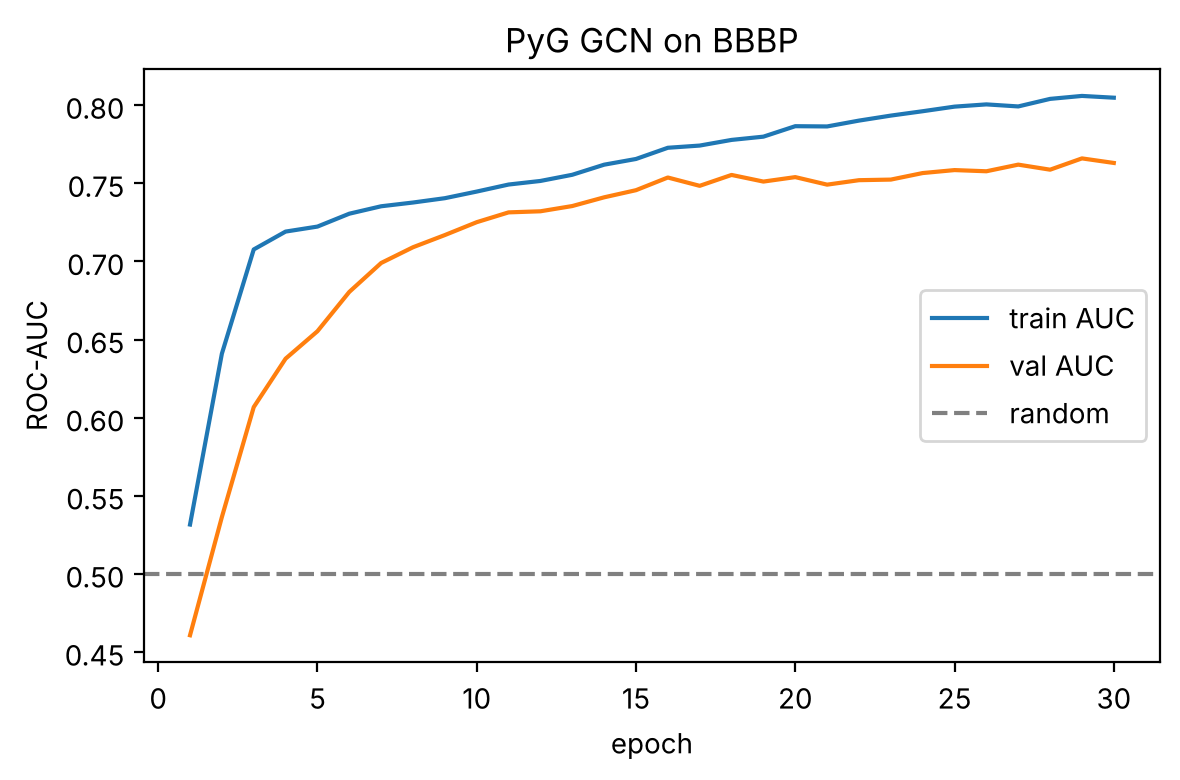

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(range(1,31), hist['tr'], label='train AUC')
plt.plot(range(1,31), hist['va'], label='val AUC')
plt.axhline(0.5, ls='--', c='grey', label='random')
plt.xlabel('epoch'); plt.ylabel('ROC-AUC'); plt.title('PyG GCN on BBBP')
plt.legend(); plt.tight_layout(); plt.show()

## Why use the library

Same model, same result — but:

- **Less code, fewer bugs.** `GCNConv` and `DataLoader` are tested by thousands of users.
- **Speed.** PyG uses sparse **scatter/gather** message passing — no dense N×N matrices like our `make_batch`. On a GPU it's dramatically faster on large graphs.
- **A menu of layers.** Swapping `GCNConv` for `GATConv` or `GINConv` is a one-line change — which is exactly how we reach state-of-the-art architectures next.
- **Ecosystem.** Standard datasets, pooling operators, explainers, and splitters are all included.

**Next — Notebook 05:** attention (**GAT**), the maximally expressive **GIN**, *honest* evaluation with **scaffold splitting**, and **explaining** which atoms drove a prediction.